
Model Evaluation
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-score: 0.9333333333333333


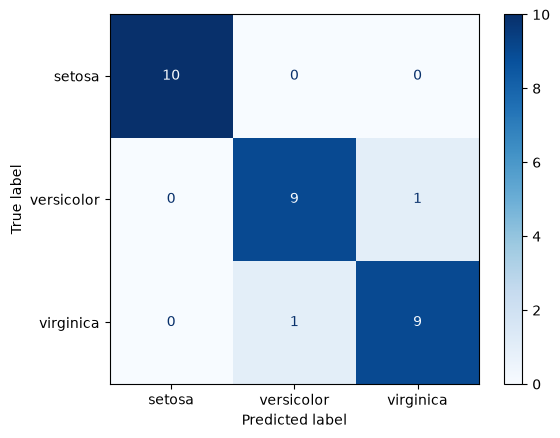


Model Deployment
Predicted species: setosa


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# -------------------------------
# Activity #1 : Implementing Logistic Regression by loading Iris dataset from sklearn library
# -------------------------------

#Data Import
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")

#Data Splitting
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Model Creation & Training

# Implementing by scaling and then model building
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train_flat)
# X_test_scaled = scaler.transform(X_test_flat)
# lr_model = LogisticRegression(max_iter=200)
# lr_model.fit(X_train_scaled, y_train)

# OR can be implemented by creating Pipeline

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=200))
])
lr_model.fit(X_train, y_train)

#Model Testing
y_pred = lr_model.predict(X_test)

#Model Evaluation
print("\nModel Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1-score:", f1_score(y_test, y_pred, average="weighted"))
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.show()

#Model Deployement
print("\nModel Deployment")
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = lr_model.predict(new_flower)
probability = lr_model.predict_proba(new_flower)

print("Predicted species:", iris.target_names[prediction[0]])